# About Dataset

Fonte: [Online Shoppers Purchasing Intention (Kaggle)](https://www.kaggle.com/datasets/imakash3011/online-shoppers-purchasing-intention-dataset), originado do repositório UCI (Sakar et al., 2018).

## Contexto

Sessões de navegação de um e-commerce ao longo de 1 ano. Cada linha é uma sessão de um usuário diferente, para evitar viés por campanha, dia especial, perfil do usuário ou período. O objetivo de negócio é prever a **propensão de compra** (a sessão termina em compra?).

## Descrição das colunas

**Comportamento de navegação (numéricas)**

- `Administrative`, `Administrative_Duration`: nº de páginas administrativas (conta, perfil) visitadas e tempo gasto nelas
- `Informational`, `Informational_Duration`: nº de páginas informativas (contato, sobre) visitadas e tempo gasto
- `ProductRelated`, `ProductRelated_Duration`: nº de páginas de produto visitadas e tempo gasto
- `BounceRates`: média da taxa de rejeição (saiu após ver uma única página) das páginas visitadas
- `ExitRates`: média da taxa de saída das páginas visitadas
- `PageValues`: valor médio das páginas visitadas antes de uma transação (e-commerce)
- `SpecialDay`: proximidade da data a um dia especial (Dia das Mães, Valentine's etc.), de 0 a 1

**Contexto da sessão (categóricas)**

- `Month`: mês da sessão
- `OperatingSystems`, `Browser`, `Region`, `TrafficType`: identificadores codificados como inteiros
- `VisitorType`: `Returning_Visitor`, `New_Visitor` ou `Other`
- `Weekend`: booleano, sessão em fim de semana

**Target**

- `Revenue`: booleano, a sessão terminou em compra

# 1 - Configuração do ambiente

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42  # seed fixa para reprodutibilidade

# 2 - Carregamento dos dados

In [2]:
path = "../data/source/online_shoppers_intention.csv"
df = pd.read_csv(path)
df.head(5)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [4]:
print(f"Shape bruto: {df.shape}")

Shape bruto: (12330, 18)


In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0


**Interpretação**:


- 12.330 sessões e 18 colunas (17 features + `Revenue`), tipos coerentes com o dicionário: 10 numéricas, `Month` e `VisitorType` como texto, `Weekend` e `Revenue` como booleanos
- `OperatingSystems`, `Browser`, `Region` e `TrafficType` vêm como inteiros, mas são **códigos de categoria** (não existe ordem entre `Region 3` e `Region 4`), então devem ser tratados como categóricas
- `Month` tem só 10 valores distintos (não existem `Jan` e `Apr`), e `May` e `Nov` concentram a maior parte das sessões
- `Returning_Visitor` representa 10.551 das 12.330 sessões (~86%)

# 3 - Análise exploratória de dados (EDA)

## 3.1 - Qualidade dos dados

### 3.1.1 - Missing values e duplicados

In [6]:
missing_values = pd.DataFrame(
    {
        "Column": df.columns,
        "Missing_Count": df.isnull().sum().values,
        "Missing_Percentage": (df.isnull().sum() / len(df) * 100).round(2).values,
    }
)
print("Colunas com missing:")
print(missing_values[missing_values["Missing_Count"] > 0])
print(f"\nTotal de missing no dataset: {df.isnull().sum().sum()}")

n_dup = df.duplicated().sum()
print(f"Linhas duplicadas: {n_dup} ({n_dup / len(df):.2%})")

Colunas com missing:
Empty DataFrame
Columns: [Column, Missing_Count, Missing_Percentage]
Index: []

Total de missing no dataset: 0
Linhas duplicadas: 125 (1.01%)


**Interpretação**:


- Dataset **sem nenhum missing value**, não é necessário imputar
- 125 linhas duplicadas (~1%). Como não há ID de sessão, não dá para afirmar que são erros (sessões curtas e parecidas podem coincidir), mas duplicatas caindo em treino e teste ao mesmo tempo inflam a métrica. Decisão a tomar no pré-processamento: remover antes do split

### 3.1.2 - Valores inválidos e ranges

In [7]:
range_checks = {
    "Contagens de páginas < 0": (
        df[["Administrative", "Informational", "ProductRelated"]] < 0
    ).any(axis=1),
    "Durações < 0": (
        df[
            [
                "Administrative_Duration",
                "Informational_Duration",
                "ProductRelated_Duration",
            ]
        ]
        < 0
    ).any(axis=1),
    "BounceRates fora de [0, 1]": ~df["BounceRates"].between(0, 1),
    "ExitRates fora de [0, 1]": ~df["ExitRates"].between(0, 1),
    "SpecialDay fora de [0, 1]": ~df["SpecialDay"].between(0, 1),
    "PageValues < 0": df["PageValues"] < 0,
    "Duração > 0 com contagem = 0": (
        ((df["Administrative"] == 0) & (df["Administrative_Duration"] > 0))
        | ((df["Informational"] == 0) & (df["Informational_Duration"] > 0))
        | ((df["ProductRelated"] == 0) & (df["ProductRelated_Duration"] > 0))
    ),
    "Contagem > 0 com duração = 0": (
        ((df["Administrative"] > 0) & (df["Administrative_Duration"] == 0))
        | ((df["Informational"] > 0) & (df["Informational_Duration"] == 0))
        | ((df["ProductRelated"] > 0) & (df["ProductRelated_Duration"] == 0))
    ),
}
for name, mask in range_checks.items():
    print(f"{name:35s}: {int(mask.sum()):>5} linhas")

Contagens de páginas < 0           :     0 linhas
Durações < 0                       :     0 linhas
BounceRates fora de [0, 1]         :     0 linhas
ExitRates fora de [0, 1]           :     0 linhas
SpecialDay fora de [0, 1]          :     0 linhas
PageValues < 0                     :     0 linhas
Duração > 0 com contagem = 0       :     0 linhas
Contagem > 0 com duração = 0       :  1069 linhas


In [8]:
# valores mínimos das durações (suspeita de sentinela negativa)
duration_cols = [
    "Administrative_Duration",
    "Informational_Duration",
    "ProductRelated_Duration",
]
df[duration_cols].min()

Administrative_Duration    0.0
Informational_Duration     0.0
ProductRelated_Duration    0.0
dtype: float64

**Interpretação**:


- Nenhum valor impossível: contagens e durações não negativas, taxas e `SpecialDay` dentro de [0, 1], `PageValues` não negativo
- Nenhuma sessão com duração positiva e contagem zero
- 1.069 sessões com contagem de páginas > 0 e duração = 0. Isso é esperado e não é erro: a duração de uma página só é medida quando o usuário navega para a página seguinte, então sessões que terminam na primeira página registram tempo 0. Esse padrão também explica as sessões com `BounceRates` = 0 e duração baixa

### 3.1.3 - Cardinalidade e tipos

In [9]:
cardinality = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "n_unique": df.nunique(),
        "exemplos": [sorted(df[c].unique())[:6] for c in df.columns],
    }
)
cardinality

,dtype,n_unique,exemplos
Administrative,int64,27,"[0, 1, 2, 3, 4, 5]"
Administrative_Duration,float64,3335,"[0.0, 1.333333333, 2.0, 3.0, 3.5, 4.0]"
Informational,int64,17,"[0, 1, 2, 3, 4, 5]"
Informational_Duration,float64,1258,"[0.0, 1.0, 1.5, 2.0, 2.5, 3.0]"
ProductRelated,int64,311,"[0, 1, 2, 3, 4, 5]"
ProductRelated_Duration,float64,9551,"[0.0, 0.5, 1.0, 2.333333333, 2.666666667, 3.0]"
BounceRates,float64,1872,"[0.0, 2.73e-05, 3.35e-05, 3.83e-05, 3.94e-05, ..."
ExitRates,float64,4777,"[0.0, 0.000175593, 0.000250438, 0.000262123, 0..."
PageValues,float64,2704,"[0.0, 0.038034542, 0.067049546, 0.093546949, 0..."
SpecialDay,float64,6,"[0.0, 0.2, 0.4, 0.6, 0.8, 1.0]"


**Interpretação**:


- `TrafficType` tem 20 códigos, `Browser` 13, `Region` 9 e `OperatingSystems` 8: cardinalidade baixa, one-hot é viável sem explosão de colunas
- `ProductRelated_Duration` e `ExitRates` têm milhares de valores distintos, o que é esperado em variáveis contínuas
- `SpecialDay` só assume 6 valores (0, 0.2, ..., 1.0), mais próxima de uma ordinal do que de uma contínua

## 3.2 - Análise da variável target

         contagem  percentual
Revenue                      
False       10422       84.53
True         1908       15.47


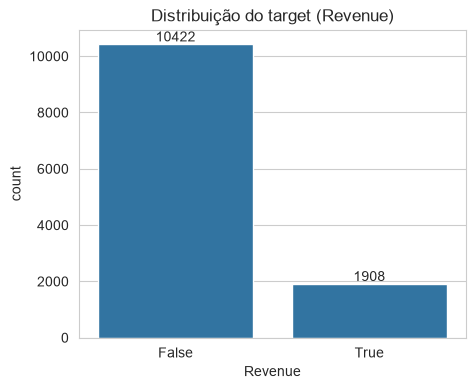

In [10]:
TARGET = "Revenue"

target_counts = df[TARGET].value_counts()
target_pct = df[TARGET].value_counts(normalize=True) * 100
print(pd.DataFrame({"contagem": target_counts, "percentual": target_pct.round(2)}))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x=TARGET, data=df, ax=ax)
for container in ax.containers:
    ax.bar_label(container)
ax.set_title("Distribuição do target (Revenue)")
plt.show()

**Interpretação**:


- **Desbalanceamento**: ~15,5% de sessões com compra (1.908) contra ~84,5% sem compra (10.422)
- Um modelo que sempre prevê "não compra" já teria **84,5% de accuracy** e seria inútil para o negócio, pois nunca identificaria quem tem propensão de compra. Por isso accuracy não serve como métrica de decisão
- Implicações: split **estratificado**, métricas sensíveis à classe positiva (PR-AUC, F1, recall/precision) e tratamento do desbalanceamento (ex.: `class_weight="balanced"`)

## 3.3 - Análise das variáveis numéricas

In [11]:
numeric_cols = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay",
]

dist_stats = pd.DataFrame(
    {
        "Skewness": df[numeric_cols].skew().round(2),
        "Kurtosis": df[numeric_cols].kurtosis().round(2),
        "% zeros": ((df[numeric_cols] == 0).mean() * 100).round(1),
        "Média": df[numeric_cols].mean().round(2),
        "Mediana": df[numeric_cols].median().round(2),
        "Máx": df[numeric_cols].max().round(2),
    }
)
dist_stats

,Skewness,Kurtosis,% zeros,Média,Mediana,Máx
Administrative,1.96,4.70,46.8,2.32,1.00,27.00
Administrative_Duration,5.62,50.56,47.9,80.82,7.50,3398.75
Informational,4.04,26.93,78.7,0.50,0.00,24.00
Informational_Duration,7.58,76.32,80.5,34.47,0.00,2549.38
ProductRelated,4.34,31.21,0.3,31.73,18.00,705.00
ProductRelated_Duration,7.26,137.17,6.1,1194.75,598.94,63973.52
BounceRates,2.95,7.72,44.8,0.02,0.00,0.20
ExitRates,2.15,4.02,0.6,0.04,0.03,0.20
PageValues,6.38,65.64,77.9,5.89,0.00,361.76
SpecialDay,3.30,9.91,89.9,0.06,0.00,1.00


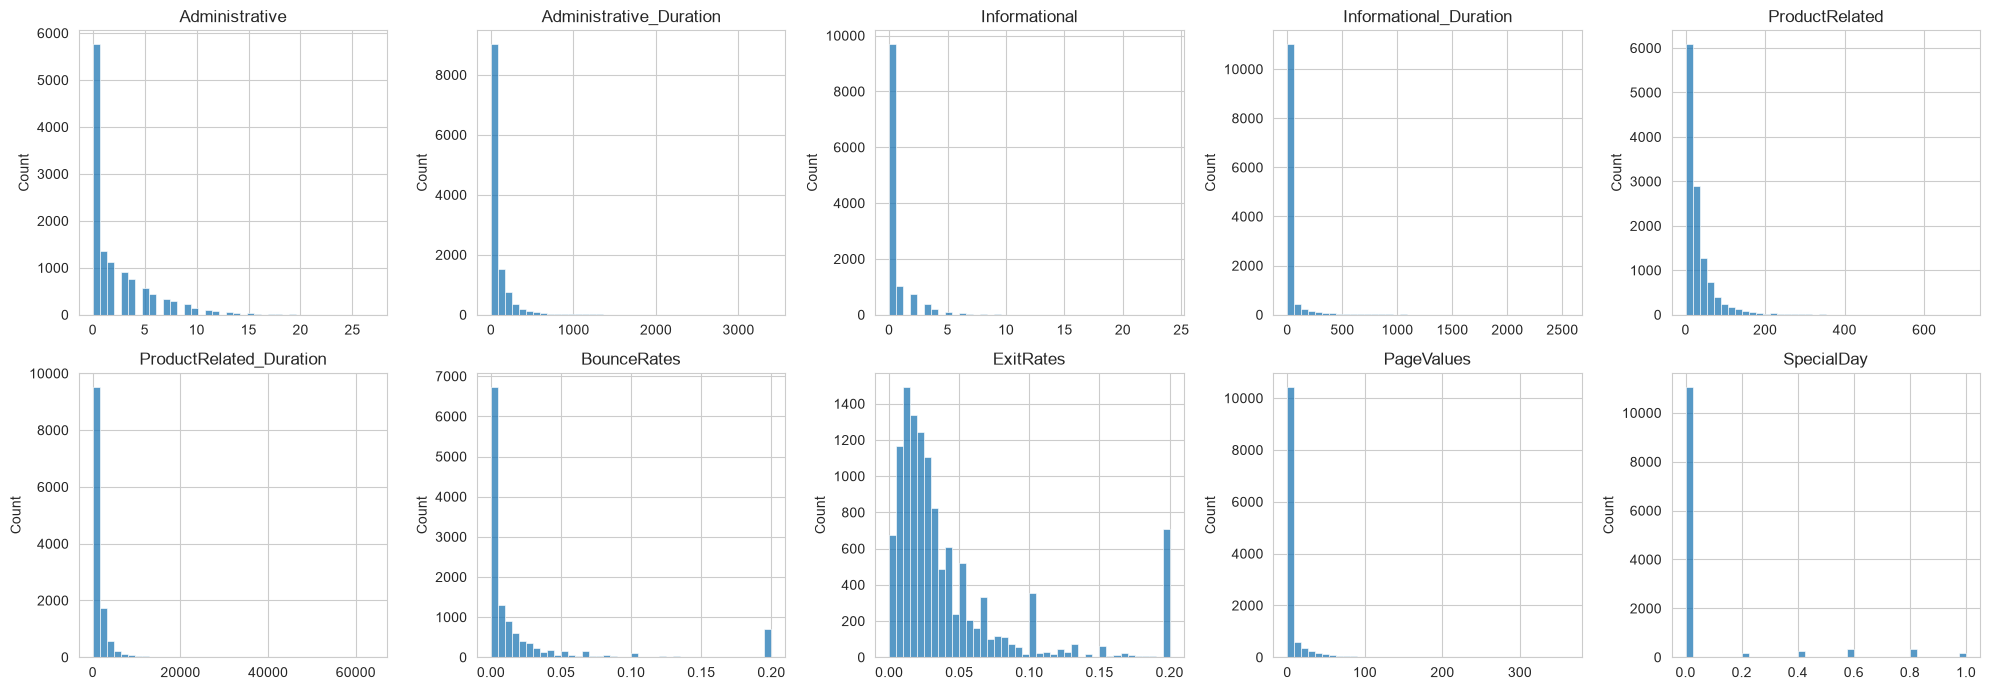

In [12]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.ravel(), numeric_cols):
    sns.histplot(df[col], bins=40, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

**Interpretação**:


- Todas as numéricas são **muito assimétricas à direita** (skewness de 2 a 7,6) com kurtosis alta, ou seja, a maioria das sessões é curta e poucas são enormes (ex.: `ProductRelated_Duration` chega a ~64 mil segundos, mais de 17 horas, contra mediana de ~600 segundos)
- Muitas variáveis são dominadas por zeros: `Informational` e `Informational_Duration` (~79 a 80%), `PageValues` (~78%), `SpecialDay` (~90%), `Administrative` e `Administrative_Duration` (~47 a 48%) e `BounceRates` (~45%)
- Implicação: para modelos lineares/escalados, vale considerar transformação (`log1p`); modelos de árvore são insensíveis a essa assimetria

### 3.3.1 - Outliers (IQR)

In [13]:
def iqr_outliers(series: pd.Series) -> int:
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).sum())


outliers = pd.DataFrame(
    {
        "Outliers (IQR)": {col: iqr_outliers(df[col]) for col in numeric_cols},
    }
)
outliers["% do total"] = (outliers["Outliers (IQR)"] / len(df) * 100).round(1)
outliers

,Outliers (IQR),% do total
Administrative,404,3.3
Administrative_Duration,1172,9.5
Informational,2631,21.3
Informational_Duration,2405,19.5
ProductRelated,987,8.0
ProductRelated_Duration,961,7.8
BounceRates,1551,12.6
ExitRates,1099,8.9
PageValues,2730,22.1
SpecialDay,1251,10.1


**Interpretação**:


- Entre 3% e 22% das linhas aparecem como outliers pelo IQR, mas isso é **efeito da assimetria e dos zeros**: quando 78% dos valores são 0, qualquer valor positivo vira "outlier" (ex.: `PageValues` 22%, `Informational` 21%)
- Esses valores não são erros e carregam informação (quem tem `PageValues` > 0 é justamente quem mais compra, ver 3.3.3). **Não vamos remover outliers**; a assimetria é tratada com transformação ou com modelos baseados em árvore

### 3.3.2 - Numéricas x target

In [14]:
df.groupby(TARGET)[numeric_cols].agg(["mean", "median"]).round(2).T

Revenue                           False    True 
Administrative          mean       2.12     3.39
                        median     0.00     2.00
Administrative_Duration mean      73.74   119.48
                        median     0.00    52.37
Informational           mean       0.45     0.79
                        median     0.00     0.00
Informational_Duration  mean      30.24    57.61
                        median     0.00     0.00
ProductRelated          mean      28.71    48.21
                        median    16.00    29.00
ProductRelated_Duration mean    1069.99  1876.21
                        median   510.19  1109.91
BounceRates             mean       0.03     0.01
                        median     0.00     0.00
ExitRates               mean       0.05     0.02
                        median     0.03     0.02
PageValues              mean       1.98    27.26
                        median     0.00    16.76
SpecialDay              mean       0.07     0.02
                        median     0.00     0.00

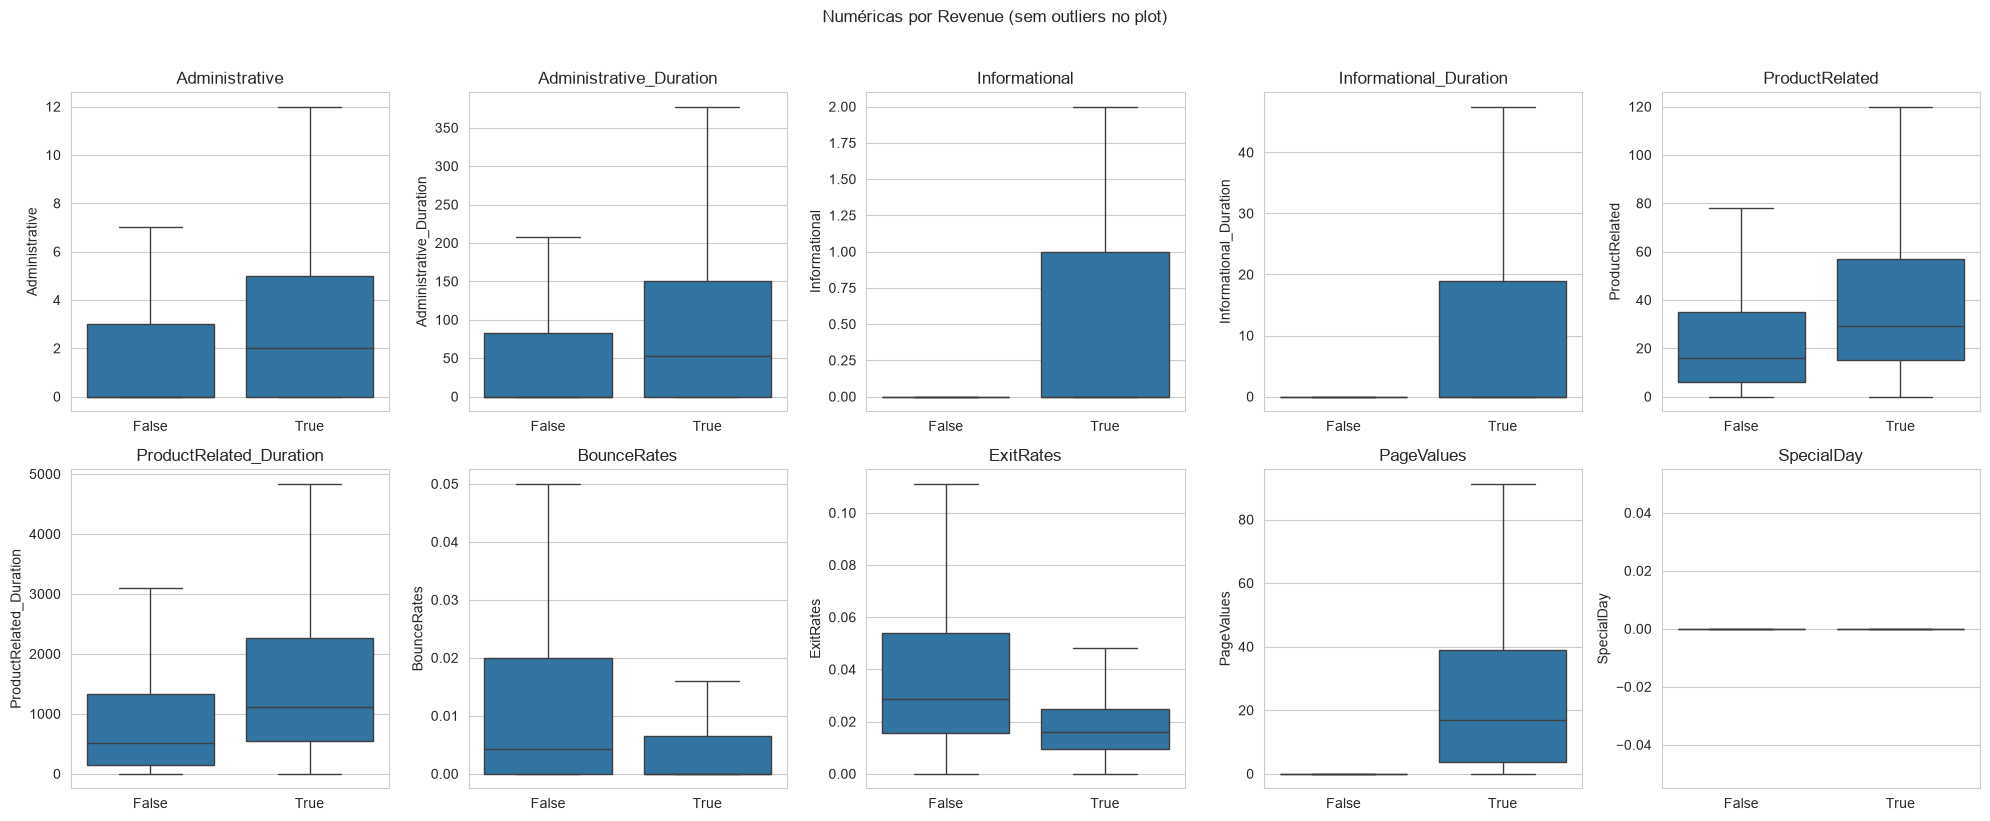

In [15]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, col in zip(axes.ravel(), numeric_cols):
    sns.boxplot(x=TARGET, y=col, data=df, ax=ax, showfliers=False)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Numéricas por Revenue (sem outliers no plot)", y=1.02)
plt.tight_layout()
plt.show()

**Interpretação**:


- Sessões com compra têm mais páginas visitadas e mais tempo em todas as categorias (ex.: `ProductRelated` média 48 contra 29; `ProductRelated_Duration` média ~1.876 contra ~1.070 s)
- `BounceRates` e `ExitRates` são **menores** em quem compra (usuário engajado não sai logo e a compra é uma saída "natural" do funil)
- `PageValues` é a diferença mais marcante: média 27,3 em quem compra contra 2,0 em quem não compra, e mediana 16,8 contra 0
- `SpecialDay` é menor entre compradores, o que parece contraintuitivo; ver 3.6

### 3.3.3 - PageValues: a feature mais associada à compra

In [16]:
has_page_value = df["PageValues"] > 0
print(
    pd.DataFrame(
        {
            "sessões": has_page_value.value_counts(),
            "taxa de compra": df.groupby(has_page_value)[TARGET].mean().round(3),
        }
    ).rename(index={False: "PageValues = 0", True: "PageValues > 0"})
)

                sessões  taxa de compra
PageValues                             
PageValues = 0     9600           0.039
PageValues > 0     2730           0.563


**Interpretação**:


- Sessões com `PageValues` = 0 têm taxa de compra de **3,9%**; com `PageValues` > 0, **56,3%** (14 vezes maior)
- É a feature mais discriminativa do dataset (correlação de 0,49 com o target, ver 3.5)
- **Atenção**: `PageValues` vem do Google Analytics e mede o valor das páginas visitadas *antes de uma transação*, portanto pode embutir parte da informação da própria compra. Para este desafio (foco em engenharia, não no modelo) mantemos a feature, mas isso deve ser citado como limitação nas lições aprendidas

## 3.4 - Análise das variáveis categóricas

In [17]:
categorical_cols = [
    "Month",
    "VisitorType",
    "Weekend",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
]

MONTH_ORDER = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]


def conversion_by_category(col: str) -> pd.DataFrame:
    grouped = df.groupby(col)[TARGET].agg(sessoes="size", taxa_compra="mean")
    grouped["taxa_compra"] = (grouped["taxa_compra"] * 100).round(1)
    return grouped

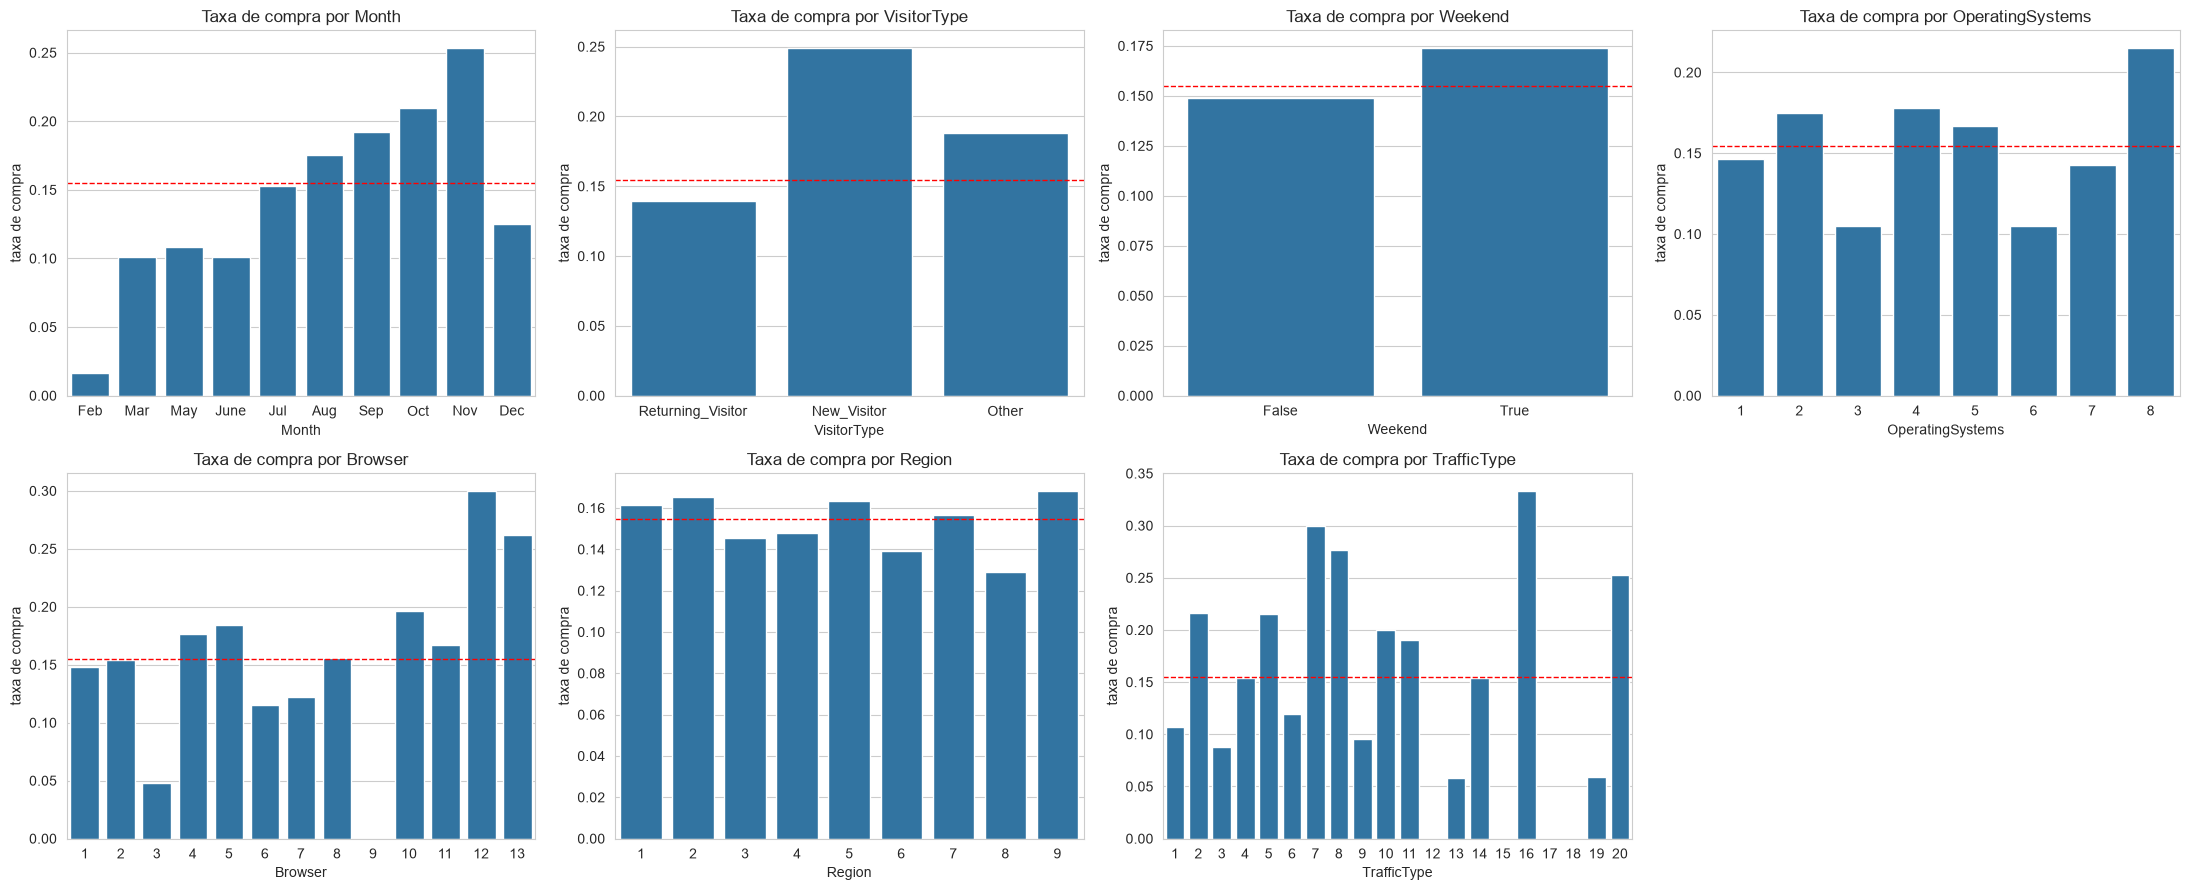

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for ax, col in zip(axes.ravel(), categorical_cols):
    order = MONTH_ORDER if col == "Month" else None
    sns.barplot(x=col, y=TARGET, data=df, order=order, ax=ax, errorbar=None)
    ax.axhline(df[TARGET].mean(), color="red", ls="--", lw=1)
    ax.set_title(f"Taxa de compra por {col}")
    ax.set_ylabel("taxa de compra")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

In [19]:
conversion_by_category("Month").reindex(MONTH_ORDER)

,sessoes,taxa_compra
Month,,
Feb,184,1.6
Mar,1907,10.1
May,3364,10.9
June,288,10.1
Jul,432,15.3
Aug,433,17.6
Sep,448,19.2
Oct,549,20.9
Nov,2998,25.4


In [20]:
conversion_by_category("VisitorType")

,sessoes,taxa_compra
VisitorType,,
New_Visitor,1694,24.9
Other,85,18.8
Returning_Visitor,10551,13.9


In [21]:
conversion_by_category("Weekend")

,sessoes,taxa_compra
Weekend,,
False,9462,14.9
True,2868,17.4


In [22]:
conversion_by_category("TrafficType").sort_values("sessoes", ascending=False)

,sessoes,taxa_compra
TrafficType,,
2,3913,21.6
1,2451,10.7
3,2052,8.8
4,1069,15.4
13,738,5.8
10,450,20.0
6,444,11.9
8,343,27.7
5,260,21.5


**Interpretação**:


- **Month**: forte sazonalidade. `Nov` tem a maior taxa (25,4%, com 2.998 sessões) e `Feb` a menor (1,6%, só 184 sessões). Os meses de maior volume (`Mar`, `May`) convertem pouco (~10 a 11%)
- **VisitorType**: `New_Visitor` converte mais (24,9%) que `Returning_Visitor` (13,9%), mesmo sendo bem menos sessões
- **Weekend**: efeito pequeno (17,4% contra 14,9%)
- **TrafficType**: variação grande (de 0% a 30%), mas vários códigos têm pouquíssimas sessões (ex.: 12, 17, 18 com 1 a 10 sessões), logo as taxas são instáveis. Um `OneHotEncoder(handle_unknown="ignore")` (e eventualmente agrupar categorias raras) é suficiente

In [23]:
# Region, Browser e OperatingSystems: variação da taxa entre categorias com volume relevante
for col in ["Region", "Browser", "OperatingSystems"]:
    print(f"--- {col} ---")
    print(conversion_by_category(col).sort_values("sessoes", ascending=False).head(6))

--- Region ---
        sessoes  taxa_compra
Region                      
1          4780         16.1
3          2403         14.5
4          1182         14.8
2          1136         16.5
6           805         13.9
7           761         15.6
--- Browser ---
         sessoes  taxa_compra
Browser                      
2           7961         15.4
1           2462         14.8
4            736         17.7
5            467         18.4
6            174         11.5
10           163         19.6
--- OperatingSystems ---
                  sessoes  taxa_compra
OperatingSystems                      
2                    6601         17.5
1                    2585         14.7
3                    2555         10.5
4                     478         17.8
8                      79         21.5
6                      19         10.5


**Interpretação**:


- `Region`, `Browser` e `OperatingSystems` têm taxas próximas da média global (~15%) entre as categorias de maior volume, ou seja, **baixo poder preditivo**. Mantemos no modelo (custo baixo), mas não esperamos que sejam relevantes
- `OperatingSystems` 3 é a exceção entre os maiores (10,5%), vale observar a importância das features depois do treino

## 3.5 - Análise de correlações

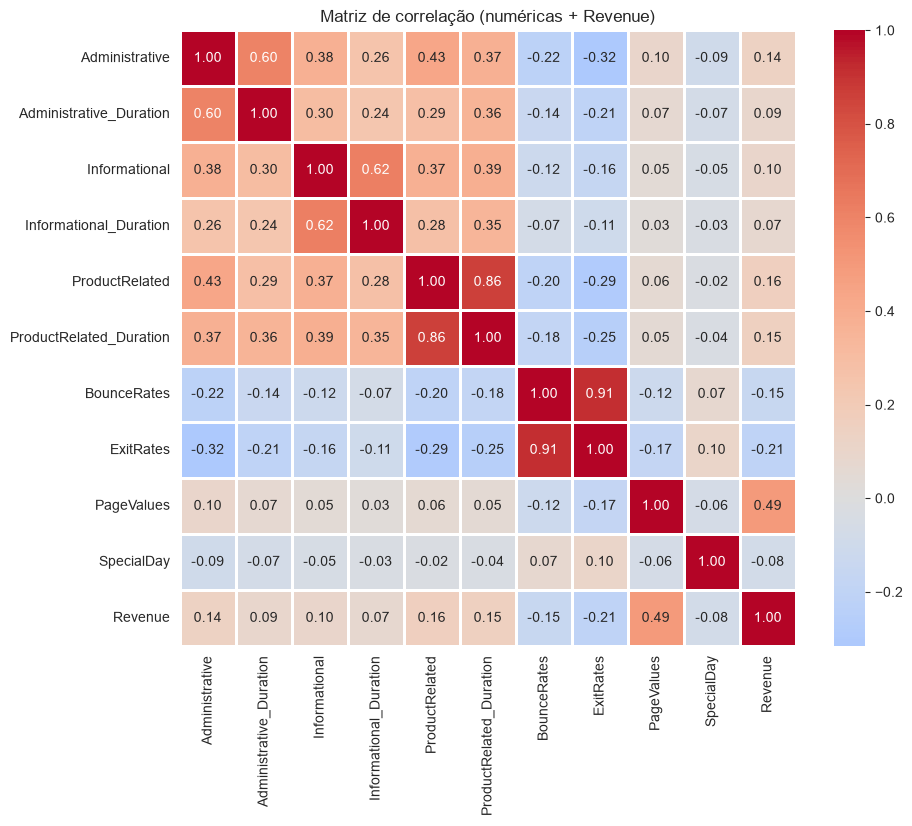

In [24]:
corr = df[numeric_cols].assign(Revenue=df[TARGET].astype(int)).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=1
)
plt.title("Matriz de correlação (numéricas + Revenue)")
plt.show()

In [25]:
# pares de features mais correlacionados entre si (|r| > 0.5)
pairs = corr.drop(index="Revenue", columns="Revenue").stack()
pairs = pairs[pairs.index.get_level_values(0) < pairs.index.get_level_values(1)]
pairs[pairs.abs() > 0.5].sort_values(ascending=False).round(2)

BounceRates     ExitRates                  0.91
ProductRelated  ProductRelated_Duration    0.86
Informational   Informational_Duration     0.62
Administrative  Administrative_Duration    0.60
dtype: float64

In [26]:
corr["Revenue"].drop("Revenue").sort_values(ascending=False).round(3)

PageValues                 0.493
ProductRelated             0.159
ProductRelated_Duration    0.152
Administrative             0.139
Informational              0.095
Administrative_Duration    0.094
Informational_Duration     0.070
SpecialDay                -0.082
BounceRates               -0.151
ExitRates                 -0.207
Name: Revenue, dtype: float64

**Interpretação**:


- **`PageValues`** é a variável mais correlacionada com o target (0,49), bem acima das demais
- Em seguida vêm as de volume de navegação (`ProductRelated`, `ProductRelated_Duration`, `Administrative`, com ~0,14 a 0,16) e `ExitRates` com correlação negativa (-0,21)
- **Multicolinearidade entre features**: `BounceRates` x `ExitRates` (0,91) e `ProductRelated` x `ProductRelated_Duration` (0,86) são quase redundantes, e `Informational`/`Administrative` com suas durações ficam em ~0,6. Não é problema para árvores; para regressão logística a regularização (L2) ajuda a lidar com isso
- Nenhuma feature isolada tem correlação linear forte, ou seja, o problema é de dificuldade moderada e o ganho está na combinação de variáveis

## 3.6 - Sazonalidade e contexto

In [27]:
# SpecialDay: taxa de compra por valor (dia especial vs. normal)
conversion_by_category("SpecialDay")

,sessoes,taxa_compra
SpecialDay,,
0.0,11079,16.5
0.2,178,7.9
0.4,243,5.3
0.6,351,8.3
0.8,325,3.4
1.0,154,6.5


In [28]:
# VisitorType x Month: o perfil do visitante muda ao longo do ano?
pd.crosstab(df["Month"], df["VisitorType"], normalize="index").reindex(
    MONTH_ORDER
).round(2)

VisitorType,New_Visitor,Other,Returning_Visitor
Month,,,
Feb,0.01,0.00,0.99
Mar,0.12,0.00,0.88
May,0.09,0.00,0.91
June,0.10,0.00,0.89
Jul,0.12,0.00,0.88
Aug,0.17,0.00,0.83
Sep,0.24,0.00,0.76
Oct,0.23,0.00,0.77
Nov,0.14,0.01,0.85


**Interpretação**:


- **SpecialDay**: sessões em dias próximos a datas especiais (>0) convertem **menos** (3 a 8%) do que sessões normais (16,5%). Provavelmente os usuários só navegam/pesquisam antes da data. O efeito é contraintuitivo, vale citar nas lições aprendidas
- **VisitorType x Month**: a proporção de novos visitantes varia ao longo do ano (de 1% em `Feb` a 24% em `Sep`). Parte do efeito de `Month` e de `VisitorType` pode estar entrelaçada, outro motivo para modelos capazes de capturar interações (ex.: Random Forest)

# 4 - Conclusões e implicações para o pipeline

Resumo do que a EDA define para o pré-processamento e a modelagem:

**Qualidade dos dados**

- Sem missing e sem valores inválidos, não há imputação
- 125 duplicatas (~1%): remover antes do split para evitar vazamento entre treino e teste
- Sem remoção de outliers: são comportamento legítimo, tratado por transformação ou por modelos de árvore

**Target e métrica**

- Desbalanceado (~15,5% positivos): split **estratificado** com seed fixa, `class_weight="balanced"` e métrica de seleção sensível à classe positiva (proposta: PR-AUC / `average_precision`), com F1, precision, recall e ROC-AUC como apoio. Accuracy é só referência (baseline trivial = 84,5%)

**Pré-processamento (`ColumnTransformer`)**

- Numéricas (10): `StandardScaler` (com `log1p` opcional para os modelos lineares)
- Categóricas: `Month`, `VisitorType`, `Weekend` e os códigos `OperatingSystems`, `Browser`, `Region`, `TrafficType` tratados como **categorias** (one-hot com `handle_unknown="ignore"`), não como números
- Converter `Revenue` e `Weekend` para inteiro

**Modelagem**

- Candidatos: regressão logística (baseline), Random Forest e Gradient Boosting, justificados pela assimetria, pelas interações (`Month` x `VisitorType`) e pela multicolinearidade
- Esperamos que `PageValues` domine a importância; citar como limitação (possível leakage parcial) no vídeo e no README